# First Move

In [1]:
import pandas as pd
import os
import json

In [2]:
df = pd.read_csv("data/north1.csv")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31668\1080754845.py:1: DtypeWarning: Columns (13,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/north1.csv")


In [3]:
df.head()

,DISTRIBUTOR,DISTRICT,AREA,CUST ID,CHANNEL,MONTH,YEAR,INPUT DATE/TGL INVOICE,TRANS ID,PRODUCT ID,...,VARIAN,GRAMASI,QTY JUAL/RETURN,SATUAN UKURAN,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,PROMO_NOTE,GROSS SALES
0,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-ORI-54,...,ORIGINAL,54 GR,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0
1,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SPI-54,...,SPICY,54 GR,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0
2,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SAL-54,...,SALTED,54 GR,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0
3,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-ORI-100,...,ORIGINAL,100 GR,0.0625,CRT,0.0625,1200000,0.0,0.0,NaN,75000.0
4,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SPI-100,...,SPICY,100 GR,0.0625,CRT,0.0625,1200000,0.0,0.0,NaN,75000.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279940 entries, 0 to 1279939
Data columns (total 21 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   DISTRIBUTOR             1279940 non-null  object 
 1   DISTRICT                1279940 non-null  object 
 2   AREA                    1279940 non-null  object 
 3   CUST ID                 1279940 non-null  object 
 4   CHANNEL                 1279940 non-null  object 
 5   MONTH                   1279940 non-null  int64  
 6   YEAR                    1279940 non-null  int64  
 7   INPUT DATE/TGL INVOICE  1270924 non-null  object 
 8   TRANS ID                1279940 non-null  object 
 9   PRODUCT ID              1279940 non-null  object 
 10  PRODUCT NAME            1279940 non-null  object 
 11  VARIAN                  1279940 non-null  object 
 12  GRAMASI                 1279940 non-null  object 
 13  QTY JUAL/RETURN         1279940 non-null  object 
 14  SA

In [5]:
df["YEAR"].unique()

array([2023, 2024, 2025, 2026])

# Cleaning

In [6]:
df[df['TRANS ID'] == '202506-238274']

,DISTRIBUTOR,DISTRICT,AREA,CUST ID,CHANNEL,MONTH,YEAR,INPUT DATE/TGL INVOICE,TRANS ID,PRODUCT ID,...,VARIAN,GRAMASI,QTY JUAL/RETURN,SATUAN UKURAN,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,PROMO_NOTE,GROSS SALES


In [7]:
print(df.isnull().sum())

DISTRIBUTOR                     0
DISTRICT                        0
AREA                            0
CUST ID                         0
CHANNEL                         0
MONTH                           0
YEAR                            0
INPUT DATE/TGL INVOICE       9016
TRANS ID                        0
PRODUCT ID                      0
PRODUCT NAME                    0
VARIAN                          0
GRAMASI                         0
QTY JUAL/RETURN                 0
SATUAN UKURAN               18642
QTY IN CRT                      0
PRICE PER CRT                   0
DISKON_%                        0
DISKON_RP                       0
PROMO_NOTE                1276239
GROSS SALES                     0
dtype: int64


In [8]:
df = df.dropna(subset=['QTY JUAL/RETURN'])

In [9]:
df['DATE'] = pd.to_datetime(df['INPUT DATE/TGL INVOICE'], errors='coerce')

In [10]:
df.loc[df['DATE'].isna(), 'INPUT DATE/TGL INVOICE'].unique()

array(['20-01-2023', '21-01-2023', '23-01-2023', ..., '2026-07-26',
       '2026-01-01', '2025-11-09'], shape=(2529,), dtype=object)

In [11]:
# Filter yang NaN
mask = df['INPUT DATE/TGL INVOICE'].isna()

# Buat date dari YEAR + MONTH + tanggal 1
df.loc[mask, 'INPUT DATE/TGL INVOICE'] = pd.to_datetime(
    df.loc[mask, ['YEAR', 'MONTH']].assign(DAY=1)
)

In [12]:
import re

def deteksi_pola(val):
    if pd.isna(val):
        return 'NULL'
    s = str(val).strip()

    if re.match(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$', s):
        return 'YYYY-MM-DD HH:MM:SS'
    elif re.match(r'^\d{4}-\d{2}-\d{2}$', s):
        return 'YYYY-MM-DD'
    elif re.match(r'^\d{2}-\d{2}-\d{4}$', s):
        return 'DD-MM-YYYY'
    elif re.match(r'^\d{2}/\d{2}/\d{4}$', s):
        return 'DD/MM/YYYY atau MM/DD/YYYY'
    elif re.match(r'^\d{2}-\d{2}-\d{2}$', s):
        return 'DD-MM-YY'
    elif re.match(r'^\d{8}$', s):
        return 'YYYYMMDD'
    elif re.match(r'^\d{4}/\d{2}/\d{2}$', s):
        return 'YYYY/MM/DD'
    elif re.match(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}$', s):
        return 'YYYY-MM-DD HH:MM'
    else:
        return f'LAIN: {s[:30]}'   # tampilkan contohnya

df['pola'] = df['INPUT DATE/TGL INVOICE'].apply(deteksi_pola)
df['pola'].value_counts()

pola
YYYY-MM-DD                    683023
YYYY-MM-DD HH:MM:SS           489128
DD-MM-YYYY                     44969
DD/MM/YYYY atau MM/DD/YYYY     14925
LAIN: 03 Dec 2024                251
                               ...  
LAIN: 02 May 2024                  2
LAIN: 04 Okt 2024                  2
LAIN: 19 Nop 2024                  1
LAIN: 27 Nov 2024                  1
LAIN: 05 Okt 2024                  1
Name: count, Length: 660, dtype: int64

In [13]:
df['DATE'] = pd.to_datetime(
    df['INPUT DATE/TGL INVOICE'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

In [14]:
df.loc[df['DATE'].isna(), 'INPUT DATE/TGL INVOICE'].unique()

array(['02 Nop 2024', '01 Nop 2024', '06 Nop 2024', '04 Nop 2024',
       '12 Nop 2024', '08 Nop 2024', '09 Nop 2024', '11 Nop 2024',
       '14 Nop 2024', '15 Nop 2024', '18 Nop 2024', '21 Nop 2024',
       '20 Nop 2024', '22 Nop 2024', '25 Nop 2024', '30 Nop 2024',
       '28 Nop 2024', '26 Nop 2024', '29 Nop 2024', '05 Nop 2024',
       '13 Nop 2024', '23 Nop 2024', '07 Nop 2024', '16 Nop 2024',
       '19 Nop 2024', '03 Des 2024', '02 Des 2024', '05 Des 2024',
       '06 Des 2024', '04 Des 2024', '11 Des 2024', '09 Des 2024',
       '10 Des 2024', '07 Des 2024', '13 Des 2024', '14 Des 2024',
       '12 Des 2024', '16 Des 2024', '17 Des 2024', '18 Des 2024',
       '20 Des 2024', '19 Des 2024', '23 Des 2024', '21 Des 2024',
       '26 Des 2024', '27 Des 2024', '24 Des 2024', '28 Des 2024',
       '31 Des 2024', '30 Des 2024', '04 Okt 2024', '05 Okt 2024',
       '07 Okt 2024', '08 Okt 2024', '09 Okt 2024', '10 Okt 2024',
       '11 Okt 2024', '12 Okt 2024', '14 Okt 2024', '15 Okt 20

In [15]:
bulan_map = {
    'Jan':'Jan','Feb':'Feb','Mar':'Mar','Apr':'Apr','Mei':'May','Jun':'Jun',
    'Jul':'Jul','Agu':'Aug','Sep':'Sep','Okt':'Oct','Nop':'Nov','Des':'Dec'
}

def parse_indo(val):
    if pd.isna(val):
        return pd.NaT
    s = str(val).strip()
    for i, e in bulan_map.items():
        s = s.replace(i, e)
    try:
        return pd.to_datetime(s, format='%d %b %Y')
    except:
        return pd.NaT

# Cuma isi yang masih NaT
mask = df['DATE'].isna() & df['INPUT DATE/TGL INVOICE'].notna()
df.loc[mask, 'DATE'] = df.loc[mask, 'INPUT DATE/TGL INVOICE'].apply(parse_indo)

In [16]:
df.loc[df['DATE'].isna(), 'INPUT DATE/TGL INVOICE'].unique()

array([], dtype=object)

In [17]:
print(df.isnull().sum())

DISTRIBUTOR                     0
DISTRICT                        0
AREA                            0
CUST ID                         0
CHANNEL                         0
MONTH                           0
YEAR                            0
INPUT DATE/TGL INVOICE          0
TRANS ID                        0
PRODUCT ID                      0
PRODUCT NAME                    0
VARIAN                          0
GRAMASI                         0
QTY JUAL/RETURN                 0
SATUAN UKURAN               18642
QTY IN CRT                      0
PRICE PER CRT                   0
DISKON_%                        0
DISKON_RP                       0
PROMO_NOTE                1276239
GROSS SALES                     0
DATE                            0
pola                            0
dtype: int64


In [18]:
df.loc[df['SATUAN UKURAN'].isnull()]

,DISTRIBUTOR,DISTRICT,AREA,CUST ID,CHANNEL,MONTH,YEAR,INPUT DATE/TGL INVOICE,TRANS ID,PRODUCT ID,...,QTY JUAL/RETURN,SATUAN UKURAN,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,PROMO_NOTE,GROSS SALES,DATE,pola
307003,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-SAL-100,...,6.0,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307004,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-HON-100,...,6.0,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307005,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-ORI-100,...,6.0,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307006,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-SPI-100,...,6.0,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307007,DIST KEDONDONG,BLORA,MIDDLE,C07097,GT,2,2024,2024-02-02 00:00:00,202402-96820,MJ-ORI-6,...,10.0,NaN,1.000000,300000,2.0,0.0,NaN,300000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471087,DIST GANDARIA,YOGYAKARTA,SOUTH,C06192,GT,7,2024,2024-07-31 00:00:00,202407-144950,MJ-ORI-12,...,40.0,NaN,0.333333,360000,0.0,0.0,NaN,120000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471088,DIST GANDARIA,YOGYAKARTA,SOUTH,C10890,GT,7,2024,2024-07-31 00:00:00,202407-143850,MJ-ORI-12,...,20.0,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471089,DIST GANDARIA,YOGYAKARTA,SOUTH,C05441,GT,7,2024,2024-07-31 00:00:00,202407-142855,MJ-ORI-12,...,20.0,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471090,DIST GANDARIA,YOGYAKARTA,SOUTH,C05983,GT,7,2024,2024-07-31 00:00:00,202407-144708,MJ-ORI-12,...,20.0,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS


In [19]:
# Mask hanya baris yang SATUAN UKURAN null
mask = df['SATUAN UKURAN'].isna()

# 1. Samakan QTY JUAL/RETURN dengan QTY IN CRT
df.loc[mask, 'QTY JUAL/RETURN'] = df.loc[mask, 'QTY IN CRT']

In [20]:
df.loc[df['SATUAN UKURAN'].isnull()]

,DISTRIBUTOR,DISTRICT,AREA,CUST ID,CHANNEL,MONTH,YEAR,INPUT DATE/TGL INVOICE,TRANS ID,PRODUCT ID,...,QTY JUAL/RETURN,SATUAN UKURAN,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,PROMO_NOTE,GROSS SALES,DATE,pola
307003,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-SAL-100,...,0.125,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307004,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-HON-100,...,0.125,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307005,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-ORI-100,...,0.125,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307006,DIST KEDONDONG,BLORA,MIDDLE,C01186,GT,2,2024,2024-02-02 00:00:00,202402-96819,MJ-SPI-100,...,0.125,NaN,0.125000,1200000,0.0,0.0,NaN,150000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
307007,DIST KEDONDONG,BLORA,MIDDLE,C07097,GT,2,2024,2024-02-02 00:00:00,202402-96820,MJ-ORI-6,...,1.0,NaN,1.000000,300000,2.0,0.0,NaN,300000.0,2024-02-02,YYYY-MM-DD HH:MM:SS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471087,DIST GANDARIA,YOGYAKARTA,SOUTH,C06192,GT,7,2024,2024-07-31 00:00:00,202407-144950,MJ-ORI-12,...,0.333333,NaN,0.333333,360000,0.0,0.0,NaN,120000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471088,DIST GANDARIA,YOGYAKARTA,SOUTH,C10890,GT,7,2024,2024-07-31 00:00:00,202407-143850,MJ-ORI-12,...,0.166667,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471089,DIST GANDARIA,YOGYAKARTA,SOUTH,C05441,GT,7,2024,2024-07-31 00:00:00,202407-142855,MJ-ORI-12,...,0.166667,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS
471090,DIST GANDARIA,YOGYAKARTA,SOUTH,C05983,GT,7,2024,2024-07-31 00:00:00,202407-144708,MJ-ORI-12,...,0.166667,NaN,0.166667,360000,0.0,0.0,NaN,60000.0,2024-07-31,YYYY-MM-DD HH:MM:SS


In [21]:
df

,DISTRIBUTOR,DISTRICT,AREA,CUST ID,CHANNEL,MONTH,YEAR,INPUT DATE/TGL INVOICE,TRANS ID,PRODUCT ID,...,QTY JUAL/RETURN,SATUAN UKURAN,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,PROMO_NOTE,GROSS SALES,DATE,pola
0,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-ORI-54,...,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0,2023-01-05,DD-MM-YYYY
1,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SPI-54,...,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0,2023-01-05,DD-MM-YYYY
2,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SAL-54,...,0.0625,CRT,0.0625,648000,0.0,0.0,NaN,40500.0,2023-01-05,DD-MM-YYYY
3,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-ORI-100,...,0.0625,CRT,0.0625,1200000,0.0,0.0,NaN,75000.0,2023-01-05,DD-MM-YYYY
4,DIST APEL,SURAKARTA,EAST,C00001,GT,1,2023,05-01-2023,202301-00001,MJ-SPI-100,...,0.0625,CRT,0.0625,1200000,0.0,0.0,NaN,75000.0,2023-01-05,DD-MM-YYYY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1279935,DIST MARKISA,TEGAL,NORTH,C07278,GT,2,2025,2025-02-25,202502-190313,MJ-SPI-6,...,-100,CRT,-100.0000,300000,0.0,0.0,NaN,-30000000.0,2025-02-25,YYYY-MM-DD
1279936,DIST MARKISA,TEGAL,NORTH,C07278,GT,3,2025,2025-03-28,202503-190316,MJ-SPI-6,...,-100,CRT,-100.0000,300000,0.0,0.0,NaN,-30000000.0,2025-03-28,YYYY-MM-DD
1279937,DIST MARKISA,TEGAL,NORTH,C07278,GT,12,2025,2025-12-20,202512-404118,MJ-SPI-6,...,-100,CRT,-100.0000,300000,0.0,0.0,NaN,-30000000.0,2025-12-20,YYYY-MM-DD
1279938,DIST MARKISA,TEGAL,NORTH,C17884,GT,1,2026,2026-01-19,202601-190348,MJ-SPI-6,...,-100,CRT,-100.0000,300000,0.0,0.0,NaN,-30000000.0,2026-01-19,YYYY-MM-DD


In [22]:
df.describe()

,MONTH,YEAR,QTY IN CRT,PRICE PER CRT,DISKON_%,DISKON_RP,GROSS SALES,DATE
count,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06,1279940
mean,6.356873e+00,2.024564e+03,5.653339e-01,7.237263e+05,8.261178e+00,4.215693e+02,3.657982e+05,2025-01-19 13:00:12.634341632
min,1.000000e+00,2.023000e+03,-1.800000e+02,2.160000e+05,-2.039849e-01,-7.718654e+04,-1.152000e+08,2023-01-02 00:00:00
25%,4.000000e+00,2.024000e+03,6.250000e-02,3.600000e+05,0.000000e+00,0.000000e+00,4.050000e+04,2024-02-27 00:00:00
50%,7.000000e+00,2.025000e+03,1.250000e-01,6.480000e+05,0.000000e+00,0.000000e+00,7.500000e+04,2025-01-31 00:00:00
75%,9.000000e+00,2.026000e+03,2.500000e-01,1.200000e+06,0.000000e+00,0.000000e+00,1.620000e+05,2026-01-05 00:00:00
max,1.200000e+01,2.026000e+03,5.280000e+02,1.500000e+06,3.140000e+05,5.993626e+06,6.336000e+08,2026-09-30 00:00:00
std,3.342335e+00,1.082119e+00,3.937760e+00,3.507451e+05,1.200948e+03,1.850636e+04,3.824030e+06,NaN


In [23]:
# 2. Isi SATUAN UKURAN dengan 'CRT'
df.loc[mask, 'SATUAN UKURAN'] = 'CRT'

In [24]:
print(df.isna().sum())

DISTRIBUTOR                     0
DISTRICT                        0
AREA                            0
CUST ID                         0
CHANNEL                         0
MONTH                           0
YEAR                            0
INPUT DATE/TGL INVOICE          0
TRANS ID                        0
PRODUCT ID                      0
PRODUCT NAME                    0
VARIAN                          0
GRAMASI                         0
QTY JUAL/RETURN                 0
SATUAN UKURAN                   0
QTY IN CRT                      0
PRICE PER CRT                   0
DISKON_%                        0
DISKON_RP                       0
PROMO_NOTE                1276239
GROSS SALES                     0
DATE                            0
pola                            0
dtype: int64


## Duplicate Data

In [25]:
df.duplicated().sum()

np.int64(5122)

## Drop Column

In [26]:
df = df.drop(columns=['pola', 'INPUT DATE/TGL INVOICE'])

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279940 entries, 0 to 1279939
Data columns (total 21 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   DISTRIBUTOR      1279940 non-null  object        
 1   DISTRICT         1279940 non-null  object        
 2   AREA             1279940 non-null  object        
 3   CUST ID          1279940 non-null  object        
 4   CHANNEL          1279940 non-null  object        
 5   MONTH            1279940 non-null  int64         
 6   YEAR             1279940 non-null  int64         
 7   TRANS ID         1279940 non-null  object        
 8   PRODUCT ID       1279940 non-null  object        
 9   PRODUCT NAME     1279940 non-null  object        
 10  VARIAN           1279940 non-null  object        
 11  GRAMASI          1279940 non-null  object        
 12  QTY JUAL/RETURN  1279940 non-null  object        
 13  SATUAN UKURAN    1279940 non-null  object        
 14  QT

In [28]:
df = df.rename(columns={
    'DISTRIBUTOR':      'DISTRIBUTOR',      # sudah Inggris
    'DISTRICT':         'DISTRICT',         # sudah Inggris
    'AREA':             'AREA',             # sudah Inggris
    'CUST ID':          'CUSTOMER_ID',
    'CHANNEL':          'CHANNEL',          # sudah Inggris
    'MONTH':            'MONTH',            # sudah Inggris
    'YEAR':             'YEAR',             # sudah Inggris
    'TRANS ID':         'TRANSACTION_ID',
    'PRODUCT ID':       'PRODUCT_ID',
    'PRODUCT NAME':     'PRODUCT_NAME',
    'VARIAN':           'VARIANT',          # atau 'FLAVOR' kalau isinya rasa
    'GRAMASI':          'WEIGHT',           # atau 'NET_WEIGHT'
    'QTY JUAL/RETURN':  'QTY',
    'SATUAN UKURAN':    'UNIT',
    'QTY IN CRT':       'QTY_CARTON',
    'PRICE PER CRT':    'PRICE_CARTON',
    'DISKON_%':         'DISCOUNT_%',
    'DISKON_RP':        'DISCOUNT_VAL',
    'PROMO_NOTE':       'PROMOTION',       # sudah Inggris
    'GROSS SALES':      'GROSS_SALES',
    'DATE':             'DATE',             # sudah Inggris
})

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279940 entries, 0 to 1279939
Data columns (total 21 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   DISTRIBUTOR     1279940 non-null  object        
 1   DISTRICT        1279940 non-null  object        
 2   AREA            1279940 non-null  object        
 3   CUSTOMER_ID     1279940 non-null  object        
 4   CHANNEL         1279940 non-null  object        
 5   MONTH           1279940 non-null  int64         
 6   YEAR            1279940 non-null  int64         
 7   TRANSACTION_ID  1279940 non-null  object        
 8   PRODUCT_ID      1279940 non-null  object        
 9   PRODUCT_NAME    1279940 non-null  object        
 10  VARIANT         1279940 non-null  object        
 11  WEIGHT          1279940 non-null  object        
 12  QTY             1279940 non-null  object        
 13  UNIT            1279940 non-null  object        
 14  QTY_CARTON      12

In [30]:
df["DISCOUNT_%"].unique()

array([ 0.00000000e+00,  9.00900901e-01,  9.19274577e-02,  1.83854915e-01,
        1.72973037e+00,  4.50447765e-01,  2.75787744e-01,  1.69513136e+00,
        8.47568367e-01,  1.80181254e-01,  1.69444389e+00,  5.40543763e-01,
        8.64862502e-01,  1.80180180e+00,  2.70271882e-01,  4.59642659e-01,
        6.30629019e-01,  2.59459288e+00,  2.54269973e+00,  3.67715201e-01,
        4.23610705e+00,  2.54137850e-01,  5.40540003e+00,  2.70269733e+00,
        5.51570117e-01,  3.60357138e-01,  4.23783646e+00,  8.30268861e+00,
        8.91706007e-01,  1.78341201e+00,  2.67511802e+00,  7.62498410e+00,
        4.32431788e+00,  5.08270329e-01,  3.45945001e+00, -6.79949529e-02,
       -3.97926229e-02, -2.03984859e-01, -4.50453136e-02, -7.95798750e-02,
        5.00000000e+00,  3.00000000e+00,  4.00000000e+00,  3.84000000e+00,
        3.00000000e+01,  2.00000000e+00,  1.00000000e+00,  1.00000000e+02,
        4.75000000e+00,  5.11000000e+00,  2.75000000e+00,  2.39000000e+00,
        5.75000000e+00,  

In [31]:
df["DISCOUNT_VAL"].unique()

array([    0., 27500.,  3000., ...,   820.,  2236.,   122.], shape=(1515,))

In [32]:
import numpy as np

# Konversi dulu ke numeric (biar aman)
df['DISCOUNT_%']   = pd.to_numeric(df['DISCOUNT_%'],   errors='coerce').fillna(0)
df['DISCOUNT_VAL'] = pd.to_numeric(df['DISCOUNT_VAL'], errors='coerce').fillna(0)

# IS_PROMOTION = True kalau salah satu terisi
df['IS_PROMOTION'] = (
    (df['DISCOUNT_%']   != 0) |
    (df['DISCOUNT_VAL'] != 0) |
    (df['PROMOTION'].notna() & (df['PROMOTION'].astype(str).str.strip() != ''))
)

In [33]:
df = df.drop(columns=['DISCOUNT_%', 'DISCOUNT_VAL', 'PROMOTION'])

## Urutan

In [34]:
urutan = [
    # Identitas transaksi
    'TRANSACTION_ID', 'DATE', 'MONTH', 'YEAR',
    # Customer / Distributor
    'DISTRIBUTOR', 'DISTRICT', 'AREA', 'CUSTOMER_ID', 'CHANNEL',
    # Produk
    'PRODUCT_ID', 'PRODUCT_NAME', 'VARIANT', 'WEIGHT',
    # Kuantitas
    'QTY', 'UNIT', 'QTY_CARTON',
    # Harga & nilai
    'PRICE_CARTON', 'GROSS_SALES',
    # Flag
    'IS_PROMOTION',
]

df = df[urutan]

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279940 entries, 0 to 1279939
Data columns (total 19 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   TRANSACTION_ID  1279940 non-null  object        
 1   DATE            1279940 non-null  datetime64[ns]
 2   MONTH           1279940 non-null  int64         
 3   YEAR            1279940 non-null  int64         
 4   DISTRIBUTOR     1279940 non-null  object        
 5   DISTRICT        1279940 non-null  object        
 6   AREA            1279940 non-null  object        
 7   CUSTOMER_ID     1279940 non-null  object        
 8   CHANNEL         1279940 non-null  object        
 9   PRODUCT_ID      1279940 non-null  object        
 10  PRODUCT_NAME    1279940 non-null  object        
 11  VARIANT         1279940 non-null  object        
 12  WEIGHT          1279940 non-null  object        
 13  QTY             1279940 non-null  object        
 14  UNIT            12

## Outliers

In [36]:
df.describe()

,DATE,MONTH,YEAR,QTY_CARTON,PRICE_CARTON,GROSS_SALES
count,1279940,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06,1.279940e+06
mean,2025-01-19 13:00:12.634341632,6.356873e+00,2.024564e+03,5.653339e-01,7.237263e+05,3.657982e+05
min,2023-01-02 00:00:00,1.000000e+00,2.023000e+03,-1.800000e+02,2.160000e+05,-1.152000e+08
25%,2024-02-27 00:00:00,4.000000e+00,2.024000e+03,6.250000e-02,3.600000e+05,4.050000e+04
50%,2025-01-31 00:00:00,7.000000e+00,2.025000e+03,1.250000e-01,6.480000e+05,7.500000e+04
75%,2026-01-05 00:00:00,9.000000e+00,2.026000e+03,2.500000e-01,1.200000e+06,1.620000e+05
max,2026-09-30 00:00:00,1.200000e+01,2.026000e+03,5.280000e+02,1.500000e+06,6.336000e+08
std,NaN,3.342335e+00,1.082119e+00,3.937760e+00,3.507451e+05,3.824030e+06


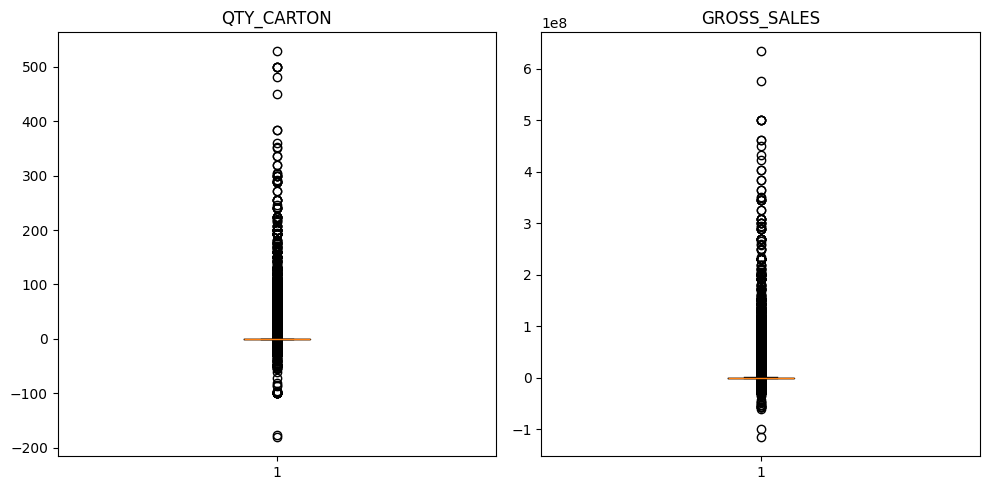

In [37]:
import matplotlib.pyplot as plt

kolom_num = ['QTY_CARTON', 'GROSS_SALES']

fig, axes = plt.subplots(1, len(kolom_num), figsize=(10, 5))
for ax, col in zip(axes, kolom_num):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [38]:
df.sort_values('GROSS_SALES', ascending=False).head(10)

,TRANSACTION_ID,DATE,MONTH,YEAR,DISTRIBUTOR,DISTRICT,AREA,CUSTOMER_ID,CHANNEL,PRODUCT_ID,PRODUCT_NAME,VARIANT,WEIGHT,QTY,UNIT,QTY_CARTON,PRICE_CARTON,GROSS_SALES,IS_PROMOTION
221947,202309-71638,2023-09-04,9,2023,DIST MANGGA,SURAKARTA,EAST,C07702,NKA,MJ-SPI-100,MEDEJOY SPICY 100 GR,SPICY,100 GR,528.0,CRT,528.0,1200000,633600000.0,False
374398,202405-116382,2024-05-06,5,2024,DIST PISANG,PURWOKERTO,WEST,C01633,NKA,MJ-SPI-100,MEDEJOY SPICY 100 GR,SPICY,100 GR,480.0,Krt,480.0,1200000,576000000.0,False
607672,202402-189893,2024-02-29,2,2024,DIST DURIAN,MAGELANG,SOUTH,C17824,GT,MJ-ORI-1000,MEDEJOY ORIGINAL 1000 GR,ORIGINAL,1000 GR,500.0,CRT,500.0,1000000,500000000.0,False
608903,202502-190214,2025-02-12,2,2025,DIST DURIAN,MAGELANG,SOUTH,C17878,GT,MJ-ORI-1000,MEDEJOY ORIGINAL 1000 GR,ORIGINAL,1000 GR,500,CRT,500.0,1000000,500000000.0,False
607676,202401-189897,2024-01-30,1,2024,DIST DURIAN,MAGELANG,SOUTH,C17824,GT,MJ-ORI-1000,MEDEJOY ORIGINAL 1000 GR,ORIGINAL,1000 GR,500.0,CRT,500.0,1000000,500000000.0,False
608902,202501-190213,2025-01-14,1,2025,DIST DURIAN,MAGELANG,SOUTH,C17878,GT,MJ-ORI-1000,MEDEJOY ORIGINAL 1000 GR,ORIGINAL,1000 GR,500,CRT,500.0,1000000,500000000.0,False
556625,202405-171958,2024-05-07,5,2024,DIST MANGGA,SURAKARTA,EAST,C07702,NKA,MJ-SPI-100,MEDEJOY SPICY 100 GR,SPICY,100 GR,384.0,DUS,384.0,1200000,460800000.0,True
478909,202409-147470,2024-09-05,9,2024,DIST PISANG,PURWOKERTO,WEST,C01633,NKA,MJ-SPI-100,MEDEJOY SPICY 100 GR,SPICY,100 GR,384.0,Ctn,384.0,1200000,460800000.0,False
608904,202512-190215,2025-12-30,12,2025,DIST DURIAN,MAGELANG,SOUTH,C17878,GT,MJ-ORI-1000,MEDEJOY ORIGINAL 1000 GR,ORIGINAL,1000 GR,450,CRT,450.0,1000000,450000000.0,False
487497,202409-150368,2024-09-06,9,2024,DIST MANGGA,SURAKARTA,EAST,C07702,NKA,MJ-SPI-100,MEDEJOY SPICY 100 GR,SPICY,100 GR,360.0,DUS,360.0,1200000,432000000.0,True


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279940 entries, 0 to 1279939
Data columns (total 19 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   TRANSACTION_ID  1279940 non-null  object        
 1   DATE            1279940 non-null  datetime64[ns]
 2   MONTH           1279940 non-null  int64         
 3   YEAR            1279940 non-null  int64         
 4   DISTRIBUTOR     1279940 non-null  object        
 5   DISTRICT        1279940 non-null  object        
 6   AREA            1279940 non-null  object        
 7   CUSTOMER_ID     1279940 non-null  object        
 8   CHANNEL         1279940 non-null  object        
 9   PRODUCT_ID      1279940 non-null  object        
 10  PRODUCT_NAME    1279940 non-null  object        
 11  VARIANT         1279940 non-null  object        
 12  WEIGHT          1279940 non-null  object        
 13  QTY             1279940 non-null  object        
 14  UNIT            12

In [40]:
df.to_csv("data/north_cleaned.csv", index=False)